# Neural ODE: reconstructing a robot arm from irregular snapshots

**Goal:** observe a 2-link robot arm at irregular times, learn a continuous-time dynamics model, and reconstruct intermediate poses.

**Important:** This lightweight demo learns from **joint angles extracted from each image** (or supplied by sensors), *not directly from image pixels*. To learn directly from pictures, add an image encoder and decoder (Latent Neural ODE). The illustrated snapshots are generated synthetically.

In [ ]:
!pip -q install torchdiffeq

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchdiffeq import odeint

np.random.seed(7)
torch.manual_seed(7)


## 1. Define a simulated robot arm and irregular observation times

Each observation consists of a timestamp and a pose $q=(q_1,q_2)$. Forward kinematics converts angles into a visible image of the robot arm. The equation below is used **only to generate training data and evaluate the reconstruction**; the Neural ODE does not know it.

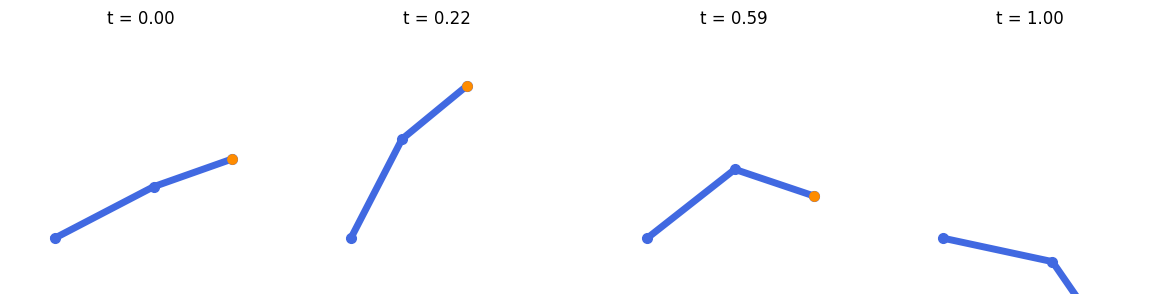

In [ ]:
L1, L2 = 1.0, 0.75

def true_angles(t):
    t = np.asarray(t)
    return np.stack([
        0.48 + 0.70 * np.sin(1.55 * np.pi * t),
       -0.58 + 0.46 * np.cos(1.28 * np.pi * t + 0.3)
    ], axis=-1)

def forward_kinematics(q):
    q1, q2 = q
    elbow = np.array([L1*np.cos(q1), L1*np.sin(q1)])
    tip = elbow + L2*np.array([np.cos(q1+q2), np.sin(q1+q2)])
    return np.vstack(([0., 0.], elbow, tip))

def draw_arm(ax, q, color='royalblue'):
    points = forward_kinematics(q)
    ax.plot(points[:,0], points[:,1], '-o', color=color, lw=5, ms=7)
    ax.scatter(*points[-1], color='darkorange', s=45, zorder=5)
    ax.set(xlim=(-0.4,1.95),ylim=(-0.5,1.85))
    ax.set_aspect('equal')
    ax.axis('off')

t_obs = np.array([0., .09, .22, .38, .59, .76, .91, 1.], dtype=np.float32)
q_obs = true_angles(t_obs).astype(np.float32)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, i in zip(axes, [0, 2, 4, 7]):
    draw_arm(ax, q_obs[i])
    ax.set_title(f't = {t_obs[i]:.2f}')
plt.tight_layout()
plt.show()

## 2. Define the neural vector field

We learn $\frac{dq}{dt}=f_\theta(q,t)$, where $q=(q_1,q_2)$ and $f_\theta$ is an MLP. Explicit time dependence lets it represent non-autonomous trajectories.

In [ ]:
class NeuralVectorField(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 48), nn.Tanh(),
            nn.Linear(48, 48), nn.Tanh(),
            nn.Linear(48, 2)
        )

    def forward(self, t, q):
        return self.net(torch.cat([q, t.reshape(1)]))

model = NeuralVectorField()

## 3. Integrate over arbitrary timestamps

We use `torchdiffeq.odeint` with the adaptive `dopri5` solver. It evaluates the Neural ODE at the requested (possibly irregular) times.

In [ ]:
# torchdiffeq integrates the neural vector field at the requested times.
# No manually implemented RK4 solver is needed.

## 4. Train only on observed snapshots

The model starts at the first observed pose and receives gradients through the numerical solver. Its parameters minimize

$${L}(\theta)=\frac{1}{N+1}\sum_i\|\hat q_\theta(t_i)-q_i\|^2.$$

No samples from intermediate times are used for training.

Final training MSE: 0.000059


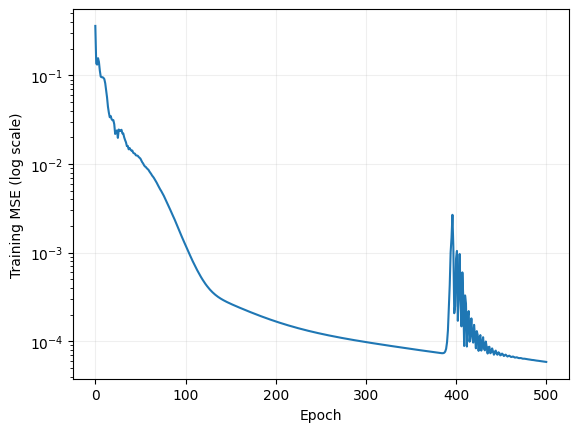

In [ ]:
times = torch.tensor(t_obs)
target = torch.tensor(q_obs)
optimizer = torch.optim.Adam(model.parameters(), lr=0.012)
losses = []

for epoch in range(501):
    optimizer.zero_grad()
    predicted = odeint(model, target[0], times, method="dopri5")
    loss = ((predicted-target)**2).mean()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f'Final training MSE: {losses[-1]:.6f}')
plt.plot(losses)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Training MSE (log scale)')
plt.grid(alpha=.2)
plt.show()

## 5. Query the Neural ODE at previously unseen times

Observe the continuous predicted angles, then render the robot arm at arbitrary timestamps. The dashed curves are ground truth **for validation only**.

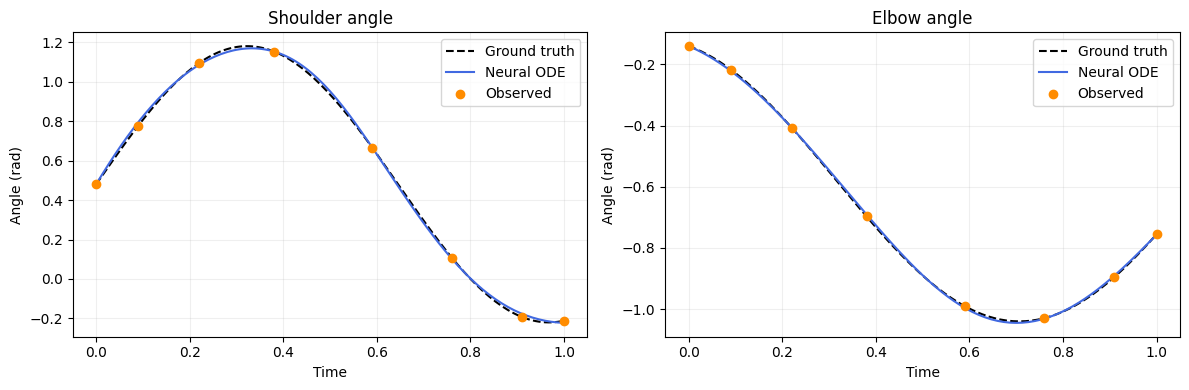

In [ ]:
t_dense = np.linspace(0, 1, 151, dtype=np.float32)
with torch.no_grad():
    q_pred = odeint(model, target[0], torch.tensor(t_dense), method="dopri5").numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, name in enumerate(['Shoulder angle', 'Elbow angle']):
    axes[j].plot(t_dense, true_angles(t_dense)[:, j], 'k--', label='Ground truth')
    axes[j].plot(t_dense, q_pred[:, j], label='Neural ODE', color='royalblue')
    axes[j].scatter(t_obs, q_obs[:, j], color='darkorange', zorder=3, label='Observed')
    axes[j].set(xlabel='Time', ylabel='Angle (rad)', title=name)
    axes[j].legend()
    axes[j].grid(alpha=.2)
plt.tight_layout()
plt.show()

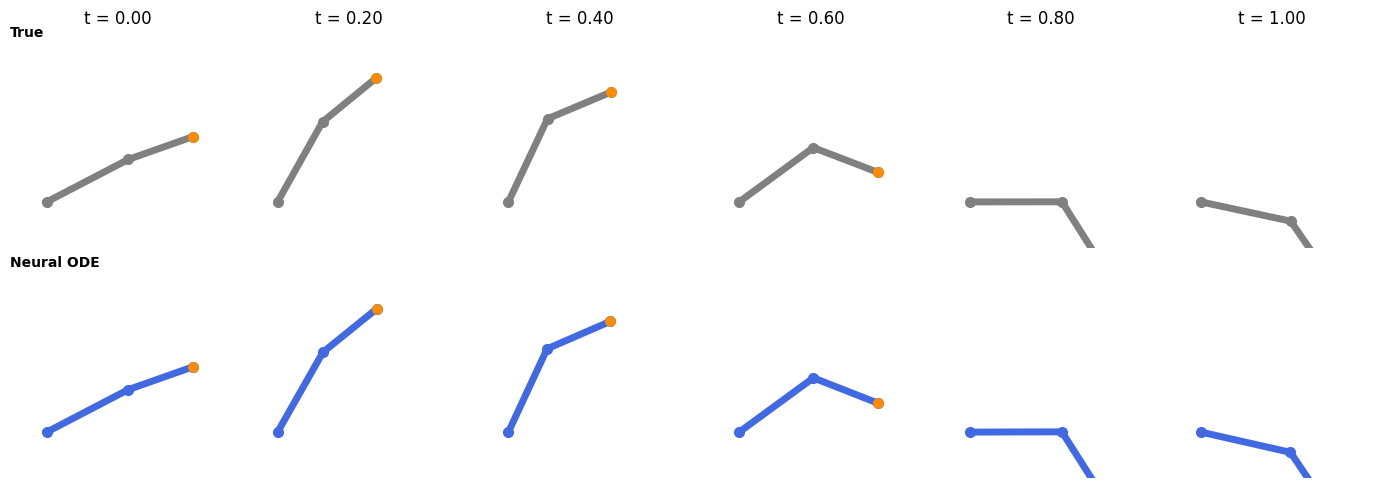

In [ ]:
query_times = np.linspace(0, 1, 6)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for col, t in enumerate(query_times):
    draw_arm(axes[0,col], true_angles(t), color='gray')
    draw_arm(axes[1,col], q_pred[int(round(t*150))], color='royalblue')
    axes[0,col].set_title(f't = {t:.2f}')
axes[0,0].text(-.4, 1.8, 'True', fontweight='bold')
axes[1,0].text(-.4, 1.8, 'Neural ODE', fontweight='bold')
plt.tight_layout()
plt.show()

## Takeaway and limitations

- **Continuous time:** the solver can reconstruct the arm at timestamps not seen during training.
- **Irregular observations:** sample times need not be evenly spaced.
- **Interpolation is not guaranteed to be correct:** sparse poses can admit many plausible trajectories.
- **From pixels to latent ODE:** use $z_0=E(I_0,\ldots,I_N; t_0,\ldots,t_N)$, $\dot z=f_\theta(z,t)$, and $\hat I(t)=D(z(t))$. That is a more ambitious image-based model and is *not* implemented in this toy example.

**Exercise:** remove half of the observation timestamps or increase the final gap. How does interpolation quality change?